# TP2 · Pruebas: 3 capas ocultas, dropout 0,3 y early stopping *(provisoria)*

> **Estado: en progreso.** Esta notebook es una prueba exploratoria posterior a la [búsqueda por etapas](02_grilla_hiperparametros.ipynb). Se publica tal como se ejecutó, con sus salidas, y todavía tiene problemas conocidos (abajo). Los resultados no reemplazan a los de las notebooks 01 y 02.

**Qué se prueba:** una MLP con **tres capas ocultas** y **dropout 0,3**, entrenada con **early stopping** (hasta 100 épocas; corta cuando la pérdida de validación no mejora durante 5 épocas y vuelve a los pesos de la mejor época). Se comparan SGD (lr = 0,01) y Adam (lr = 0,0003) con la misma semilla.

**Resultados (Colab, GPU T4, semilla 42):**

| Corrida | Arquitectura real | Mejor época | Valid acc* | Test acc |
|---|---|---|---|---|
| Ej. 11, SGD 0,01 | 512-256-128 | 45 (cortó en 50) | 89,0 % (mejor época) | — |
| Ej. 13, SGD 0,01 | 128-64-128 | 69 (cortó en 74) | 88,2 % | — |
| Ej. 13, **Adam 0,0003** (elegido) | 128-64-128 | 19 (cortó en 24) | 88,5 % | **87,8 %** |
| Semillas 0-2, SGD | 128-64-128 | 68–78 | 89,0 ± 0,3 % | — |
| Semillas 0-2, Adam | 128-64-128 | 32–37 | 89,1 ± 0,3 % | — |

\* Salvo en la primera fila, es la accuracy de validación de la **última** época (5 después de la mejor), que es lo que imprime la notebook (ver problema 2).

**Problemas conocidos (para corregir en la próxima versión):**

1. **La arquitectura de los Ej. 13 en adelante no es la que se quería.** `FashionMLP` ahora tiene tres capas (`h1=512, h2=256, h3=128`), pero `run_experiment` sigue llamando `FashionMLP(dropout_p, h1, h2)` con `h1=128, h2=64`. Así, todas las corridas de `run_experiment` (SGD contra Adam, semillas, learning rates y el modelo evaluado en test) usaron **784 → 128 → 64 → 128 → 10**, no 784 → 512 → 256 → 128 → 10. Sólo la corrida del Ej. 11 usó 512-256-128. *Arreglo:* en `run_experiment`, usar `h1=512, h2=256, h3=128` y `FashionMLP(dropout_p, h1, h2, h3)`.
2. **Las tablas leen la última época, no la mejor.** Con early stopping el modelo vuelve a los pesos de la mejor época, pero `h["valid_acc"][-1]` es la de la última (5 épocas después). La selección y las tablas deberían usar `h["valid_acc"][best_epoch - 1]` (`run_experiment` tendría que devolver también `best_epoch`).
3. `verbose=False` no tiene efecto: `fit_early_stopping` imprime todas las épocas, por eso las salidas son largas.
4. Los experimentos del Ej. 18 (dropout, épocas, capacidad y tabla final) quedaron sin ejecutar y se sacaron de esta versión; queda sólo el de learning rate de SGD.

> **EN:** Work-in-progress experiment (in Spanish): three hidden layers, dropout 0.3 and early stopping (patience 5, up to 100 epochs), SGD vs Adam. Published as run. Known issue: from exercise 13 on, `run_experiment` built a 784-128-64-128-10 network instead of the intended 784-512-256-128-10, so those results (Adam selected, 87.8 % test accuracy) are for the smaller network. Tables also read the last epoch instead of the best one.

## Ejercicio 1) Preparar el entorno

### 1.1) Importar librerías

Usaremos las mismas herramientas básicas que en la guía anterior: PyTorch, `torchvision`, `DataLoader` y Matplotlib.

In [ ]:
import random

import matplotlib.pyplot as plt
import numpy as np
import torch

from torch import nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

### 1.2) Reproducibilidad y dispositivo

Fijamos semillas y elegimos automáticamente GPU si está disponible.

In [ ]:
# 1.2) Reproducibilidad y dispositivo
SEED = 42

def set_seed(seed):
    """Fija todas las fuentes de azar que usamos: random de Python, NumPy y PyTorch."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", device)

Dispositivo: cuda


In [ ]:
# 2.1) Transformación: píxeles 0..255 -> [0,1] (ToTensor) -> [-1,1] (Normalize)
transform = transforms.Compose([
    transforms.ToTensor(),                  # (28,28) uint8 0..255  ->  (1,28,28) float 0..1
    transforms.Normalize((0.5,), (0.5,)),   # x_norm = (x - 0.5) / 0.5  ->  [-1, 1]
])

full_train = datasets.FashionMNIST(root="./data", train=True,  download=True, transform=transform)
test_set   = datasets.FashionMNIST(root="./data", train=False, download=True, transform=transform)

# Precarga: aplicamos la transformación UNA vez y guardamos todo como tensores en memoria.
# El resultado es idéntico (la transformación no tiene azar) y el entrenamiento es ~10 veces más rápido,
# porque el DataLoader ya no convierte imagen por imagen en cada época.
from torch.utils.data import TensorDataset

def to_tensor_dataset(ds):
    xs, ys = zip(*DataLoader(ds, batch_size=10_000))
    return TensorDataset(torch.cat(xs), torch.cat(ys))

full_train = to_tensor_dataset(full_train)
test_set   = to_tensor_dataset(test_set)

# Comprobación de la observación de la guía: la media NO queda en 0
x_all = torch.stack([full_train[i][0] for i in range(5000)])   # 5000 imágenes alcanzan para estimar
print(f"min = {x_all.min():.2f}, max = {x_all.max():.2f}")
print(f"media = {x_all.mean():.3f}, desvío = {x_all.std():.3f}")

100%|██████████| 26.4M/26.4M [00:01<00:00, 20.8MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 313kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 5.73MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 45.6MB/s]


min = -1.00, max = 1.00
media = -0.428, desvío = 0.709


### 2.2) *Train*, *validation* y *test*

Usaremos la misma metodología que en la guía del *autoencoder*:

- 50.000 imágenes para *train*;
- 10.000 imágenes para *validation*;
- 10.000 imágenes oficiales para *test*.

No visualizaremos nuevamente el *dataset* (ya lo hicimos en la guía de práctico del *Autoencoder*). Nos concentraremos directamente en la **tarea de clasificación**.

In [ ]:
# 2.2) Train / validation / test
generator = torch.Generator().manual_seed(SEED)       # el corte 50.000 / 10.000 queda fijo
train_set, valid_set = random_split(full_train, [50_000, 10_000], generator=generator)

print("train:", len(train_set), " validation:", len(valid_set), " test:", len(test_set))

train: 50000  validation: 10000  test: 10000


### 2.3) Nombres de las clases

Fashion-MNIST codifica las categorías con **números enteros** de `0` a `9`.

El siguiente **diccionario** sólo se utilizará para traducir las **etiquetas numéricas** a **nombres legibles** cuando analicemos las predicciones.

In [ ]:
# 2.3) Nombres de las clases
class_names = {
    0: "T-shirt/top",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle boot",
}
print(class_names[6])

Shirt


In [ ]:
# 3) DataLoaders
BATCH_SIZE = 100

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
valid_loader = DataLoader(valid_set, batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(test_set,  batch_size=BATCH_SIZE, shuffle=False)

images, labels = next(iter(train_loader))
print("images.shape =", tuple(images.shape))   # (100, 1, 28, 28)
print("labels.shape =", tuple(labels.shape))   # (100,)
print("primeras etiquetas:", labels[:10].tolist())

images.shape = (100, 1, 28, 28)
labels.shape = (100,)
primeras etiquetas: [3, 6, 1, 2, 2, 6, 2, 3, 7, 0]


## Ejercicio 5) Definir la red de clasificación

Usaremos una MLP **completamente conectada**:

$$
784
\longrightarrow
128
\longrightarrow
64
\longrightarrow
10.
$$

Para un *mini-batch*:

$$
(B,1,28,28)
\longrightarrow
(B,784)
\longrightarrow
(B,128)
\longrightarrow
(B,64)
\longrightarrow
(B,10).
$$

La última capa produce 10 *logits*. No agregamos `Softmax` al modelo porque `CrossEntropyLoss` trabaja directamente con *logits*.

Incluiremos `Dropout(p=0.2)` después de las activaciones ocultas.

> **En esta prueba** la red tiene **tres** capas ocultas (512 → 256 → 128) y `DROPOUT_P = 0.3`, no la arquitectura 784 → 128 → 64 → 10 del texto de arriba, que es el de la guía original.

In [ ]:
# 5) Red de clasificación: 784 -> 512 -> 256 -> 128 -> 10 (tres capas ocultas)
class FashionMLP(nn.Module):
    def __init__(self, dropout_p=0.2, h1=512, h2=256, h3=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, h1),
            nn.ReLU(),
            nn.Dropout(dropout_p),
            nn.Linear(h1, h2),
            nn.ReLU(),
            nn.Dropout(dropout_p),
            nn.Linear(h2, h3),
            nn.ReLU(),
            nn.Dropout(dropout_p),
            nn.Linear(h3, 10),

        )

    def forward(self, x):
        return self.net(x)

DROPOUT_P = 0.3

### 5.1) Comprobar dimensiones

Antes de entrenar, verificamos el *forward pass*.

Para $B$ imágenes y 10 clases esperamos:

$$
(B,1,28,28)
\longrightarrow
(B,10).
$$

In [ ]:
# 5.1) Comprobar dimensiones
set_seed(SEED)
model = FashionMLP(DROPOUT_P).to(device)

with torch.no_grad():
    logits = model(images.to(device))
print("entrada:", tuple(images.shape), "-> salida:", tuple(logits.shape))

n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("parámetros entrenables:", n_params)

entrada: (100, 1, 28, 28) -> salida: (100, 10)
parámetros entrenables: 567434


In [ ]:
# 6) Función de pérdida
loss_fn = nn.CrossEntropyLoss()      # recibe logits (B,10) y etiquetas enteras (B,)

# Comprobación: CrossEntropyLoss = promedio de -log(softmax(z)[y])
manual = -torch.log_softmax(logits, dim=1)[torch.arange(len(labels)), labels.to(device)].mean()
print(f"CrossEntropyLoss = {loss_fn(logits, labels.to(device)).item():.4f}   manual = {manual.item():.4f}")
print(f"referencia ln(10) = {np.log(10):.4f}  (pérdida de una red que no sabe nada)")

CrossEntropyLoss = 2.2948   manual = 2.2948
referencia ln(10) = 2.3026  (pérdida de una red que no sabe nada)


In [ ]:
# 7) Optimizador
OPTIMIZER = "SGD"     # "SGD" o "Adam"
SGD_LR  = 0.01
ADAM_LR = 0.0003
EPOCHS   = 100         # tope máximo
PATIENCE = 5

In [ ]:
# 8) Una época de entrenamiento
def train_one_epoch(model, data_loader, loss_fn, optimizer, device):
    model.train()                                   # 1. modo entrenamiento (Dropout activo)
    for images, labels in data_loader:
        images = images.to(device)                  # 2. al dispositivo
        labels = labels.to(device)
        optimizer.zero_grad()                       # 3. borrar gradientes viejos
        logits = model(images)                      # 4. forward
        loss = loss_fn(logits, labels)              # 5. Cross-Entropy
        loss.backward()                             # 6. backpropagation (calcula gradientes)
        optimizer.step()                            # 7. actualiza los pesos

In [ ]:
# 9) Evaluación: pérdida y accuracy, sin tocar los pesos
def evaluate(model, data_loader, loss_fn, device):
    model.eval()                                    # Dropout apagado
    total_loss, correct, n = 0.0, 0, 0
    with torch.no_grad():                           # no se arma el grafo de gradientes
        for images, labels in data_loader:
            images = images.to(device)
            labels = labels.to(device)
            logits = model(images)
            loss = loss_fn(logits, labels)
            b = labels.size(0)
            total_loss += loss.item() * b           # loss es promedio del batch: lo pasamos a suma
            predictions = logits.argmax(dim=1)      # clase de mayor logit
            correct += (predictions == labels).sum().item()
            n += b
    return total_loss / n, correct / n

In [ ]:
import copy

def fit_early_stopping(model, optimizer, train_loader, max_epochs=100, patience=5):
    """Entrena hasta max_epochs, corta si valid loss no mejora en `patience` épocas
    seguidas y deja el modelo con los pesos de la mejor época."""
    history = {"train_loss": [], "valid_loss": [], "train_acc": [], "valid_acc": []}
    best_loss, best_epoch, best_state, waited = float("inf"), 0, None, 0
    for epoch in range(1, max_epochs + 1):
        train_one_epoch(model, train_loader, loss_fn, optimizer, device)
        tr_loss, tr_acc = evaluate(model, train_eval_loader, loss_fn, device)
        va_loss, va_acc = evaluate(model, valid_loader, loss_fn, device)
        history["train_loss"].append(tr_loss); history["train_acc"].append(tr_acc)
        history["valid_loss"].append(va_loss); history["valid_acc"].append(va_acc)
        print(f"época {epoch:2d} | train loss {tr_loss:.4f} | valid loss {va_loss:.4f} acc {va_acc:.4f}")
        if va_loss < best_loss:                      # mejoró: guardo estos pesos
            best_loss, best_epoch, waited = va_loss, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:                                        # no mejoró: cuento una época más de espera
            waited += 1
            if waited >= patience:
                print(f"Early stopping en la época {epoch}: mejor época = {best_epoch}")
                break
    model.load_state_dict(best_state)                # vuelvo a los pesos de la mejor época
    return history, best_epoch

In [ ]:
# 10) Crear el modelo y el optimizador
set_seed(SEED)
model = FashionMLP(DROPOUT_P).to(device)

if OPTIMIZER == "SGD":
    optimizer = torch.optim.SGD(model.parameters(), lr=SGD_LR)
else:
    optimizer = torch.optim.Adam(model.parameters(), lr=ADAM_LR)
print(optimizer)

SGD (
Parameter Group 0
    dampening: 0
    differentiable: False
    foreach: None
    fused: None
    lr: 0.01
    maximize: False
    momentum: 0
    nesterov: False
    weight_decay: 0
)


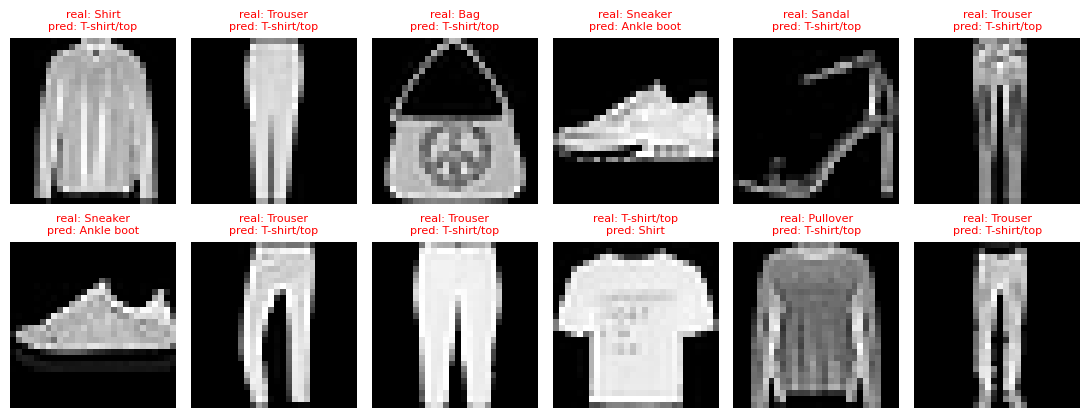

Antes de entrenar: valid loss = 2.2968, valid acc = 0.1345  (azar: ln10 = 2.3026, acc = 0.10)


In [ ]:
# 10.1) Predicciones antes de entrenar (sobre validation, no test)
rng_state = torch.get_rng_state()     # guardamos el estado del azar: iter(DataLoader) lo consume
images_v, labels_v = next(iter(valid_loader))
model.eval()
with torch.no_grad():
    pred_v = model(images_v.to(device)).argmax(dim=1).cpu()

fig, axes = plt.subplots(2, 6, figsize=(11, 4.4))
for ax, img, y, p in zip(axes.flat, images_v, labels_v, pred_v):
    ax.imshow(0.5 * img.squeeze() + 0.5, cmap="gray")
    ax.set_title(f"real: {class_names[y.item()]}\npred: {class_names[p.item()]}", fontsize=8,
                 color="green" if p == y else "red")
    ax.axis("off")
plt.tight_layout(); plt.show()

loss0, acc0 = evaluate(model, valid_loader, loss_fn, device)
print(f"Antes de entrenar: valid loss = {loss0:.4f}, valid acc = {acc0:.4f}  (azar: ln10 = 2.3026, acc = 0.10)")
torch.set_rng_state(rng_state)        # así el entrenamiento del Ej. 11 coincide con run_experiment("Adam", ...)

In [ ]:
# 11) Entrenar
# Para evaluar train usamos un loader SIN shuffle: no consume el azar del train_loader.
train_eval_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=False)

history = {"train_loss": [], "valid_loss": [], "train_acc": [], "valid_acc": []}
history, best_epoch = fit_early_stopping(model, optimizer, train_loader, max_epochs=EPOCHS, patience=PATIENCE)

época  1 | train loss 1.0313 | valid loss 1.0407 acc 0.6385
época  2 | train loss 0.7017 | valid loss 0.7181 acc 0.7322
época  3 | train loss 0.6088 | valid loss 0.6254 acc 0.7637
época  4 | train loss 0.5620 | valid loss 0.5793 acc 0.7839
época  5 | train loss 0.5227 | valid loss 0.5393 acc 0.8038
época  6 | train loss 0.4989 | valid loss 0.5167 acc 0.8134
época  7 | train loss 0.4702 | valid loss 0.4867 acc 0.8241
época  8 | train loss 0.4559 | valid loss 0.4761 acc 0.8274
época  9 | train loss 0.4389 | valid loss 0.4578 acc 0.8350
época 10 | train loss 0.4278 | valid loss 0.4495 acc 0.8371
época 11 | train loss 0.4125 | valid loss 0.4326 acc 0.8421
época 12 | train loss 0.4020 | valid loss 0.4229 acc 0.8448
época 13 | train loss 0.3923 | valid loss 0.4150 acc 0.8500
época 14 | train loss 0.3866 | valid loss 0.4085 acc 0.8531
época 15 | train loss 0.3761 | valid loss 0.4015 acc 0.8546
época 16 | train loss 0.3699 | valid loss 0.3971 acc 0.8554
época 17 | train loss 0.3607 | valid los

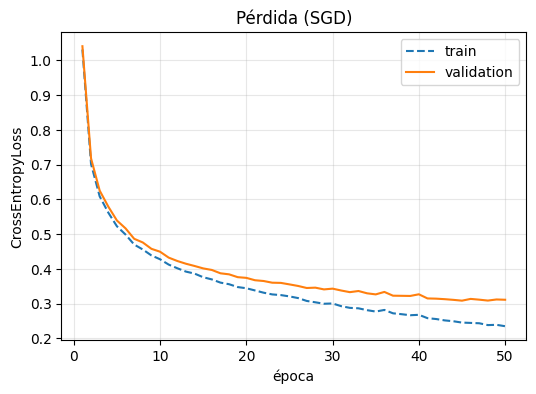

In [ ]:
# 12) Pérdida en función de las épocas
epochs = range(1, len(history["train_loss"]) + 1)
plt.figure(figsize=(6, 4))
plt.plot(epochs, history["train_loss"], "--", label="train")
plt.plot(epochs, history["valid_loss"], "-", label="validation")
plt.xlabel("época"); plt.ylabel("CrossEntropyLoss"); plt.title(f"Pérdida ({OPTIMIZER})")
plt.legend(); plt.grid(alpha=.3); plt.show()

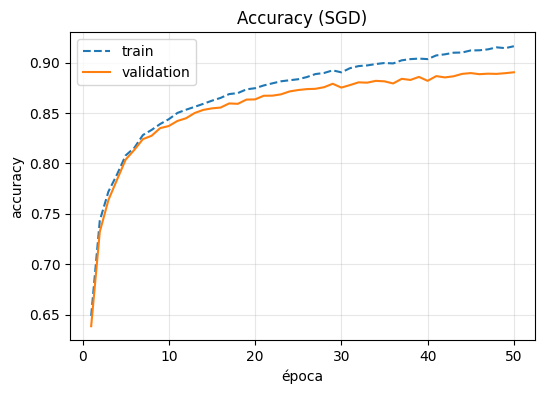

In [ ]:
# 12) Accuracy en función de las épocas
plt.figure(figsize=(6, 4))
plt.plot(epochs, history["train_acc"], "--", label="train")
plt.plot(epochs, history["valid_acc"], "-", label="validation")
plt.xlabel("época"); plt.ylabel("accuracy"); plt.title(f"Accuracy ({OPTIMIZER})")
plt.legend(); plt.grid(alpha=.3); plt.show()

### 13.1) Función para ejecutar un experimento completo

`make_optimizer()` crea el optimizador a partir de su nombre y `run_experiment()` ejecuta un entrenamiento completo, igual al de los Ejercicios 10 y 11, y devuelve el modelo entrenado y su `history`.

Para evaluar *train* usamos un `DataLoader` **sin** `shuffle`: el orden no afecta a la evaluación y así no consumimos números aleatorios del generador que determina el orden de los *mini-batches* de entrenamiento.

In [ ]:
# 13.1) Un experimento completo en una función
def make_optimizer(name, params, lr):
    if name == "SGD":
        return torch.optim.SGD(params, lr=lr)
    if name == "Adam":
        return torch.optim.Adam(params, lr=lr)
    raise ValueError(f"optimizador desconocido: {name}")


def run_experiment(opt_name, lr, seed=SEED, epochs=EPOCHS, dropout_p=DROPOUT_P, h1=128, h2=64, verbose=True):
    set_seed(seed)                                                    # todo el azar queda fijado por seed
    train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
    model = FashionMLP(dropout_p, h1, h2).to(device)
    optimizer = make_optimizer(opt_name, model.parameters(), lr)
    history = {"train_loss": [], "valid_loss": [], "train_acc": [], "valid_acc": []}
    history, best_epoch = fit_early_stopping(model, optimizer, train_loader, max_epochs=epochs, patience=PATIENCE)
    return model, history

> ⚠️ **Ojo (problema conocido 1):** esta función crea `FashionMLP(dropout_p, h1, h2)` con `h1=128, h2=64`, y `h3` queda en su valor por defecto (128). Por eso, desde acá todas las corridas usan la red **784 → 128 → 64 → 128 → 10**, no la de 512-256-128 de la celda del Ej. 5.

### 13.2) Entrenar ambas configuraciones

Entrenamos SGD y Adam con la **misma semilla** y los mismos hiperparámetros, salvo el optimizador y su *learning rate*. Guardamos cada resultado en el diccionario `results`.

In [ ]:
# 13.2) SGD y Adam con la misma semilla
configs = {"SGD": SGD_LR, "Adam": ADAM_LR}
results = {}
for name, lr in configs.items():
    print(name)
    results[name] = run_experiment(name, lr)

print()
print(f"{'optimizador':<12}{'lr':>8}{'valid loss':>12}{'valid acc':>11}")
for name, (m, h) in results.items():
    print(f"{name:<12}{configs[name]:>8}{h['valid_loss'][-1]:>12.4f}{h['valid_acc'][-1]:>11.4f}")

SGD
época  1 | train loss 1.2015 | valid loss 1.2089 acc 0.5897
época  2 | train loss 0.8127 | valid loss 0.8251 acc 0.6891
época  3 | train loss 0.6813 | valid loss 0.6959 acc 0.7404
época  4 | train loss 0.6221 | valid loss 0.6384 acc 0.7549
época  5 | train loss 0.5810 | valid loss 0.5985 acc 0.7703
época  6 | train loss 0.5541 | valid loss 0.5711 acc 0.7786
época  7 | train loss 0.5331 | valid loss 0.5505 acc 0.8008
época  8 | train loss 0.5076 | valid loss 0.5248 acc 0.8101
época  9 | train loss 0.4923 | valid loss 0.5096 acc 0.8154
época 10 | train loss 0.4717 | valid loss 0.4922 acc 0.8255
época 11 | train loss 0.4554 | valid loss 0.4742 acc 0.8332
época 12 | train loss 0.4415 | valid loss 0.4615 acc 0.8380
época 13 | train loss 0.4348 | valid loss 0.4591 acc 0.8366
época 14 | train loss 0.4236 | valid loss 0.4479 acc 0.8428
época 15 | train loss 0.4136 | valid loss 0.4357 acc 0.8428
época 16 | train loss 0.4040 | valid loss 0.4289 acc 0.8465
época 17 | train loss 0.3958 | valid

### 13.3) Comparar las curvas

Graficamos ambas configuraciones juntas: línea continua para *validation* y línea discontinua para *train*.

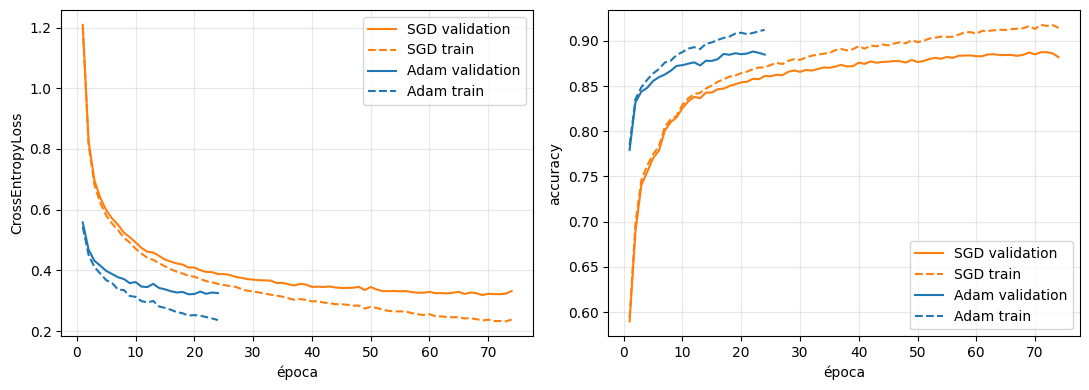

In [ ]:
# 13.3) Curvas de ambas configuraciones
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
colors = {"SGD": "tab:orange", "Adam": "tab:blue"}
for name, (m, h) in results.items():
    ep = range(1, len(h["train_loss"]) + 1)          # cada optimizador con su propio largo
    ax1.plot(ep, h["valid_loss"], "-",  color=colors[name], label=f"{name} validation")
    ax1.plot(ep, h["train_loss"], "--", color=colors[name], label=f"{name} train")
    ax2.plot(ep, h["valid_acc"],  "-",  color=colors[name], label=f"{name} validation")
    ax2.plot(ep, h["train_acc"],  "--", color=colors[name], label=f"{name} train")
ax1.set_xlabel("época"); ax1.set_ylabel("CrossEntropyLoss"); ax1.grid(alpha=.3); ax1.legend()
ax2.set_xlabel("época"); ax2.set_ylabel("accuracy"); ax2.grid(alpha=.3); ax2.legend()
plt.tight_layout(); plt.show()

### 13.4) (Opcional) Variabilidad entre semillas

Una única corrida por configuración no permite saber si una diferencia en *validation* es **real** o es producto del azar (inicialización, orden de los *mini-batches*, *Dropout*).

Repitiendo cada configuración con varias semillas podemos estimar la media y el desvío estándar de las métricas, y preguntarnos: **¿es la diferencia entre SGD y Adam mayor que la variabilidad entre corridas?**

> Esta celda entrena $2\times3=6$ modelos, por lo que puede demorar varios minutos.

In [ ]:
# 13.4) (Opcional) Variabilidad entre semillas: 2 optimizadores x 3 semillas
SEEDS = [0, 1, 2]
seed_results = {name: [] for name in configs}
for name, lr in configs.items():
    for s in SEEDS:
        _, h = run_experiment(name, lr, seed=s, verbose=False)
        seed_results[name].append((h["valid_loss"][-1], h["valid_acc"][-1]))
        print(f"{name} seed={s}: valid loss {h['valid_loss'][-1]:.4f}, valid acc {h['valid_acc'][-1]:.4f}")

print()
for name, vals in seed_results.items():
    v = np.array(vals)
    print(f"{name:<5} valid loss = {v[:,0].mean():.4f} ± {v[:,0].std(ddof=1):.4f}   "
          f"valid acc = {v[:,1].mean():.4f} ± {v[:,1].std(ddof=1):.4f}")

época  1 | train loss 1.1796 | valid loss 1.1895 acc 0.5728
época  2 | train loss 0.7971 | valid loss 0.8117 acc 0.6969
época  3 | train loss 0.6771 | valid loss 0.6954 acc 0.7381
época  4 | train loss 0.6165 | valid loss 0.6353 acc 0.7518
época  5 | train loss 0.5754 | valid loss 0.5939 acc 0.7667
época  6 | train loss 0.5448 | valid loss 0.5650 acc 0.7862
época  7 | train loss 0.5172 | valid loss 0.5358 acc 0.8049
época  8 | train loss 0.4950 | valid loss 0.5131 acc 0.8138
época  9 | train loss 0.4793 | valid loss 0.4983 acc 0.8183
época 10 | train loss 0.4615 | valid loss 0.4790 acc 0.8285
época 11 | train loss 0.4517 | valid loss 0.4708 acc 0.8302
época 12 | train loss 0.4377 | valid loss 0.4584 acc 0.8334
época 13 | train loss 0.4288 | valid loss 0.4489 acc 0.8364
época 14 | train loss 0.4183 | valid loss 0.4379 acc 0.8433
época 15 | train loss 0.4108 | valid loss 0.4332 acc 0.8454
época 16 | train loss 0.4048 | valid loss 0.4269 acc 0.8482
época 17 | train loss 0.3943 | valid los

### 13.5) Fijar la configuración seleccionada

Elegir el optimizador **a partir de los resultados sobre *validation*** y recuperar el modelo entrenado y su `history` correspondientes.

A partir de aquí, `model` es el **modelo final**: el que se evaluará sobre *test* en los ejercicios siguientes. Sus curvas de entrenamiento son las que corresponde mostrar en el informe.

In [ ]:
# 13.5) Configuración seleccionada (según validation, última época)
best = max(results, key=lambda name: results[name][1]["valid_acc"][-1])
print("Seleccionado:", best)

SELECTED = best
model, history = results[SELECTED]

Seleccionado: Adam


In [ ]:
# 14) Evaluación final sobre test (una sola vez)
test_loss, test_acc = evaluate(model, test_loader, loss_fn, device)
print(f"{SELECTED}: test loss = {test_loss:.4f}, test acc = {test_acc:.4f}")

Adam: test loss = 0.3475, test acc = 0.8780


## Ejercicio 15) Visualizar errores de clasificación sobre *test*

Ahora sí podemos observar imágenes concretas del conjunto de *test* porque la configuración ya fue seleccionada.

Las imágenes **bien** clasificadas aportan poca información. Mostraremos en cambio imágenes **mal clasificadas**: observarlas ayuda a entender qué tipo de errores comete la red y si resultan razonables desde el punto de vista visual.

Como las imágenes están normalizadas a `[-1,1]`, para visualizarlas recuperamos el intervalo `[0,1]` invirtiendo la transformación: $x = 0.5\,x_{\mathrm{norm}} + 0.5$.

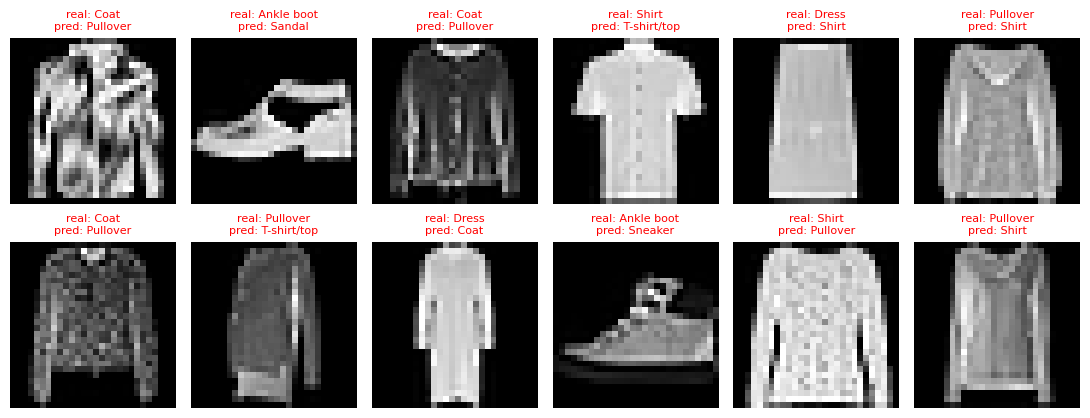

errores totales en test: 1220 de 10000


In [ ]:
# 15) Errores de clasificación sobre test
model.eval()
all_preds, all_labels, wrong = [], [], []
with torch.no_grad():
    for images, labels in test_loader:
        preds = model(images.to(device)).argmax(dim=1).cpu()
        all_preds.append(preds); all_labels.append(labels)
        for img, y, p in zip(images, labels, preds):
            if p != y and len(wrong) < 12:
                wrong.append((img, y.item(), p.item()))
all_preds = torch.cat(all_preds); all_labels = torch.cat(all_labels)

fig, axes = plt.subplots(2, 6, figsize=(11, 4.4))
for ax, (img, y, p) in zip(axes.flat, wrong):
    ax.imshow(0.5 * img.squeeze() + 0.5, cmap="gray")       # deshacer la normalización
    ax.set_title(f"real: {class_names[y]}\npred: {class_names[p]}", fontsize=8, color="red")
    ax.axis("off")
plt.tight_layout(); plt.show()
print("errores totales en test:", (all_preds != all_labels).sum().item(), "de", len(all_labels))

## Ejercicio 16) *Accuracy* por clase

La *accuracy* global puede ocultar diferencias entre categorías.

Para cada clase $k$ calculamos:

$$
\mathrm{accuracy}_k
=
\frac{\mathrm{correctos\ de\ la\ clase}\ k}
{\mathrm{ejemplos\ de\ la\ clase}\ k}.
$$

Esta evaluación se hace sobre el conjunto *test* **después de haber seleccionado el modelo**.

In [ ]:
# 16) Accuracy por clase (test)
for k in range(10):
    mask = all_labels == k
    acc_k = (all_preds[mask] == k).float().mean().item()
    print(f"{k} {class_names[k]:<12} {acc_k:.3f}")

0 T-shirt/top  0.836
1 Trouser      0.961
2 Pullover     0.768
3 Dress        0.885
4 Coat         0.838
5 Sandal       0.967
6 Shirt        0.658
7 Sneaker      0.948
8 Bag          0.972
9 Ankle boot   0.947


### 16.1) Matriz de confusión normalizada

La *accuracy* por clase resume cuántos ejemplos de cada clase fueron clasificados correctamente, pero no muestra **con qué otras clases se confunden los errores**.

Para obtener esa información utilizaremos una **matriz de confusión normalizada**.

Definimos una matriz $C$ de tamaño $10\times10$ donde:

- cada **fila** corresponde a la **clase verdadera**;
- cada **columna** corresponde a la **clase predicha**;
- $C_{ij}$ cuenta cuántos ejemplos cuya clase verdadera es $i$ fueron clasificados como clase $j$.

Por ejemplo:

$$
C_{6,0}
$$

indica cuántas imágenes cuya clase verdadera es `Shirt` fueron clasificadas como `T-shirt/top`.

La diagonal

$$
C_{00},C_{11},\ldots,C_{99}
$$

contiene las clasificaciones correctas.

Para facilitar la comparación entre clases, normalizaremos cada fila:

$$
C^{(\mathrm{norm})}_{ij}
=
\frac{C_{ij}}
{\sum_{k=0}^{9}C_{ik}}.
$$

Entonces cada fila suma aproximadamente 1:

$$
\sum_{j=0}^{9} C^{(\mathrm{norm})}_{ij}=1.
$$

De esta forma, cada elemento puede interpretarse como una **proporción de ejemplos de la clase verdadera $i$ que fueron asignados a la clase $j$**.

En una matriz de confusión normalizada ideal:

- la diagonal tendría valores cercanos a 1;
- los valores fuera de la diagonal serían cercanos a 0.

> **Importante:** esta matriz se calcula sobre `test_loader` porque ya hemos seleccionado la configuración final del modelo usando *validation*.

> **Clase 12/11:** la matriz se arma con las **clases predichas** (`argmax` de los logits), no con probabilidades. Las probabilidades sólo intervienen en la pérdida, y eso lo hace `CrossEntropyLoss` por dentro.

In [ ]:
# 16.1) Matriz de confusión: filas = clase verdadera, columnas = clase predicha
C = torch.zeros(10, 10, dtype=torch.long)
for y, p in zip(all_labels, all_preds):
    C[y, p] += 1

C_norm = C.float() / C.sum(dim=1, keepdim=True)     # cada fila suma 1
print("sumas por fila:", C_norm.sum(dim=1).numpy().round(3))

# Las confusiones más grandes (fuera de la diagonal)
off = C_norm.clone(); off.fill_diagonal_(0)
top = torch.topk(off.flatten(), 6)
for val, idx in zip(top.values, top.indices):
    i, j = divmod(idx.item(), 10)
    print(f"{class_names[i]:>12} -> {class_names[j]:<12} {val:.3f}")

sumas por fila: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
       Shirt -> T-shirt/top  0.129
    Pullover -> Coat         0.126
 T-shirt/top -> Shirt        0.113
       Shirt -> Pullover     0.089
       Shirt -> Coat         0.078
    Pullover -> Shirt        0.076


#### Visualización de la matriz

Representaremos la matriz normalizada como una imagen en escala de colores.

Para interpretar el gráfico:

- el eje vertical indica la **clase verdadera**;
- el eje horizontal indica la **clase predicha**;
- los valores de la diagonal representan **clasificaciones correctas**;
- los valores fuera de la diagonal muestran los pares de clases que la red confunde.

Como la matriz está normalizada por filas, los valores se encuentran entre 0 y 1.

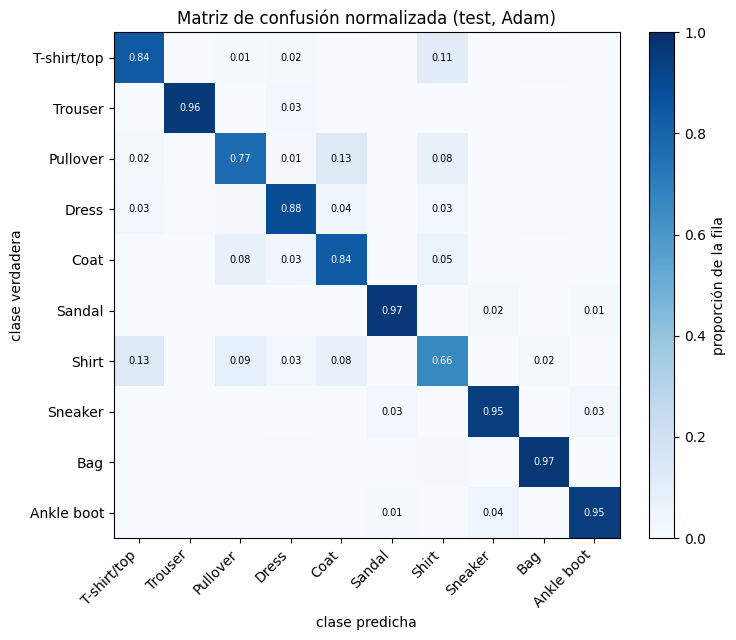

In [ ]:
# Visualización de la matriz normalizada
fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(C_norm.numpy(), cmap="Blues", vmin=0, vmax=1)
names = [class_names[k] for k in range(10)]
ax.set_xticks(range(10)); ax.set_xticklabels(names, rotation=45, ha="right")
ax.set_yticks(range(10)); ax.set_yticklabels(names)
ax.set_xlabel("clase predicha"); ax.set_ylabel("clase verdadera")
for i in range(10):
    for j in range(10):
        v = C_norm[i, j].item()
        if v >= 0.01:
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if v > 0.5 else "black")
fig.colorbar(im, ax=ax, fraction=0.046, label="proporción de la fila")
ax.set_title(f"Matriz de confusión normalizada (test, {SELECTED})")
plt.tight_layout(); plt.show()

#### Cómo interpretar el resultado

La diagonal de la matriz permite observar, clase por clase, qué proporción fue clasificada correctamente.

Por ejemplo, si para una determinada clase aparece:

$$
C^{(\mathrm{norm})}_{ii}=0.91,
$$

significa que aproximadamente el 91 % de los ejemplos de esa clase fueron clasificados correctamente.

Un valor fuera de la diagonal, por ejemplo:

$$
C^{(\mathrm{norm})}_{ij}=0.08,
$$

significa que aproximadamente el 8 % de los ejemplos cuya clase verdadera es $i$ fueron confundidos con la clase $j$.

La matriz de confusión complementa la *accuracy* global porque permite responder preguntas como:

- ¿qué clases son fáciles de reconocer?
- ¿qué clases son más difíciles?
- ¿qué pares de clases se confunden frecuentemente?
- ¿los errores tienen una estructura visual razonable?

En Fashion-MNIST es especialmente interesante observar posibles confusiones entre categorías visualmente semejantes, por ejemplo prendas de la parte superior del cuerpo.

### 18.1) Learning rate con SGD

In [ ]:
sgd_lr_results = {}
for lr in [0.001, 0.01, 0.05]:
    _, h = run_experiment("SGD", lr, verbose=False)
    sgd_lr_results[lr] = h
    print(f"SGD lr={lr:<6}: valid loss {h['valid_loss'][-1]:.4f}, valid acc {h['valid_acc'][-1]:.4f}")

época  1 | train loss 2.2795 | valid loss 2.2816 acc 0.1583
época  2 | train loss 2.2537 | valid loss 2.2561 acc 0.2370
época  3 | train loss 2.2117 | valid loss 2.2146 acc 0.3243
época  4 | train loss 2.1356 | valid loss 2.1395 acc 0.3648
época  5 | train loss 2.0019 | valid loss 2.0072 acc 0.4066
época  6 | train loss 1.8030 | valid loss 1.8091 acc 0.4440
época  7 | train loss 1.5816 | valid loss 1.5884 acc 0.4767
época  8 | train loss 1.4054 | valid loss 1.4126 acc 0.5162
época  9 | train loss 1.2820 | valid loss 1.2894 acc 0.5695
época 10 | train loss 1.1947 | valid loss 1.2024 acc 0.5852
época 11 | train loss 1.1268 | valid loss 1.1346 acc 0.6065
época 12 | train loss 1.0723 | valid loss 1.0806 acc 0.6125
época 13 | train loss 1.0264 | valid loss 1.0352 acc 0.6266
época 14 | train loss 0.9846 | valid loss 0.9941 acc 0.6478
época 15 | train loss 0.9478 | valid loss 0.9574 acc 0.6709
época 16 | train loss 0.9139 | valid loss 0.9241 acc 0.6667
época 17 | train loss 0.8854 | valid los